In [1]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("Understandability_Scores_Processed.csv", index_col= 0)

In [20]:
#Get demographic info
import statistics as st
import numpy as np
df_demo = pd.read_csv("prolific_demographic_export_6a9185e0c2087fb87e0ec276.csv")
df_demo = df_demo[df_demo['Status'] == 'APPROVED']
print(df_demo['Age'].min())
print(df_demo['Age'].max())
st.mean(pd.to_numeric(df_demo['Age']))

df_demo.Nationality.value_counts()*100/len(df_demo)

18
72


Nationality
United Kingdom    61.344538
United States     36.134454
Ireland            2.521008
Name: count, dtype: float64

In [2]:
min_med = df.groupby(['Dataset','Feature'])['Average Score'].mean()[1].min()
max_med = df.groupby(['Dataset','Feature'])['Average Score'].mean()[1].max()
range_med = max_med - min_med
min_phone = df.groupby(['Dataset','Feature'])['Average Score'].mean()[2].min()
max_phone = df.groupby(['Dataset','Feature'])['Average Score'].mean()[2].max()
range_phone = max_phone - min_phone

print("Range Medical Dataset: ", range_med, '\n',
    "Range Phone Dataset: ", range_phone)

print("Percentage Change Medical Dataset: ", 0.24/range_med*100, '\n',
    "Percentage Change Phone Dataset: ", 0.20/range_phone*100)

Range Medical Dataset:  1.0606182795698924 
 Range Phone Dataset:  1.007070707070707
Percentage Change Medical Dataset:  22.62831073374731 
 Percentage Change Phone Dataset:  19.859578736208626


In [3]:
print(min_med, max_med, min_phone, max_phone)

2.943548387096774 4.004166666666666 3.515151515151515 4.522222222222222


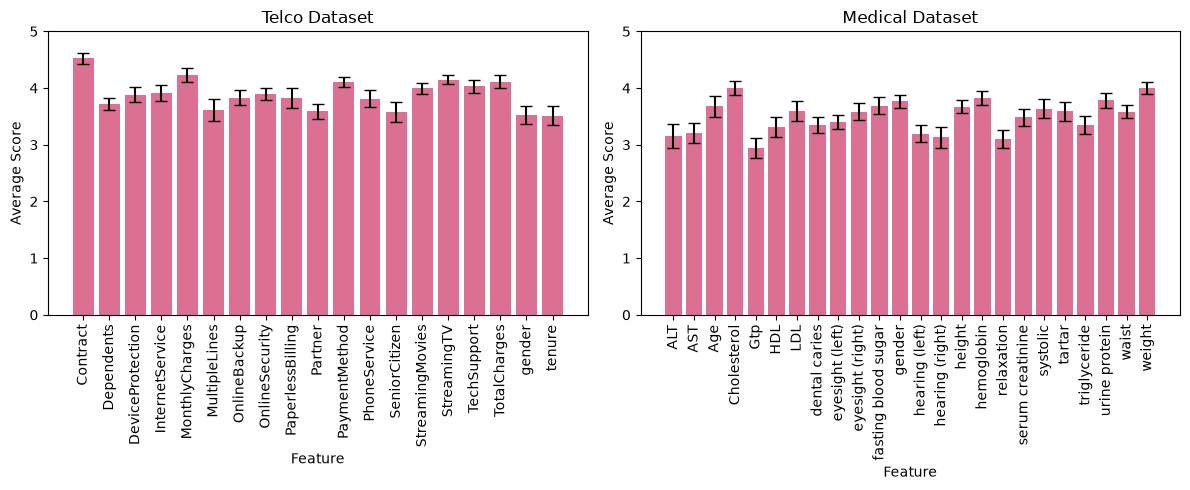

In [4]:
datasets = df["Dataset"].dropna().unique()

dataset_labels = {
    1: "Medical Dataset",
    2: "Telco Dataset",
}

fig, axes = plt.subplots(1, len(datasets), figsize=(6 * len(datasets), 5), squeeze=False)
axes = axes.flatten()
colours = ['orange', 'steelblue']

for ax, dataset, c in zip(axes, datasets, colours):
    grouped = df[df["Dataset"] == dataset].groupby("Feature", dropna=False)["Average Score"]
    feature_means = grouped.mean()
    feature_errs = grouped.sem()  # standard error of the mean; use grouped.std() for std dev

    ax.bar(
        feature_means.index.astype(str),
        feature_means.values,
        yerr=feature_errs.values,
        capsize=4,
        color='palevioletred',
        ecolor="black",
    )
    ax.set_title(dataset_labels.get(dataset, dataset))
    ax.set_xlabel("Feature")
    ax.set_ylabel("Average Score")
    ax.tick_params(axis="x", rotation = 90)
    ax.set_ylim(0, 5)

plt.tight_layout()
plt.show()

In [5]:
df[df["Dataset"] == 1].groupby("Feature", dropna=False)["Average Score"].mean().min()

np.float64(2.943548387096774)

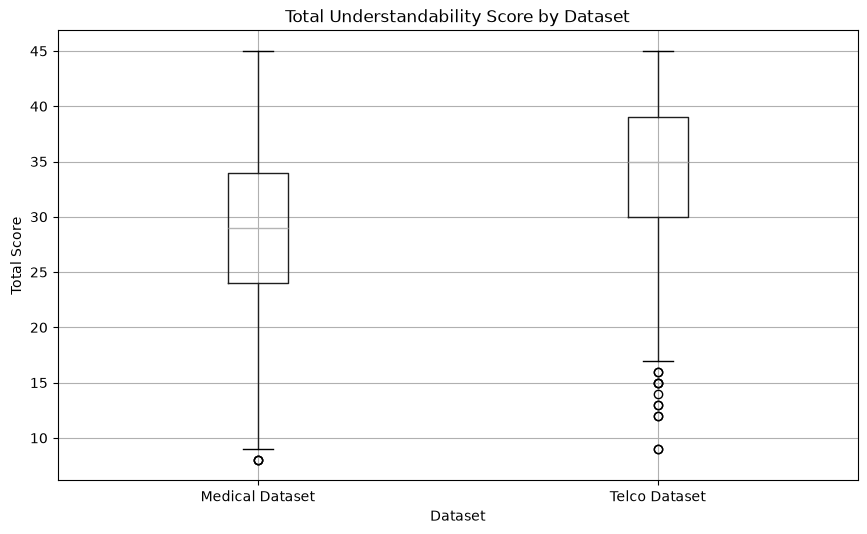

In [6]:
plt.figure(figsize=(10, 6))
df.boxplot(column='Total Score', by='Dataset', ax=plt.gca())
plt.suptitle('')  # Remove the automatic title
plt.title('Total Understandability Score by Dataset')
plt.xlabel('Dataset')
plt.ylabel('Total Score')
ax = plt.gca()
ax.set_xticklabels(['Medical Dataset', 'Telco Dataset'])
plt.show()

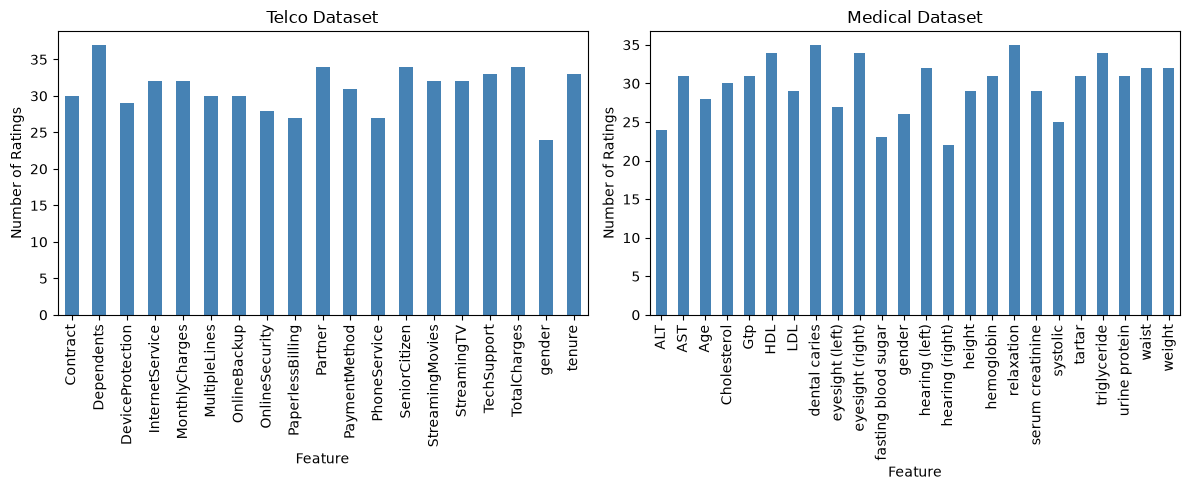

In [7]:
# Create one chart per dataset, showing the average score by feature
datasets = df["Dataset"].dropna().unique()

dataset_labels = {
    1: "Medical Dataset",
    2: "Telco Dataset",
    # add mappings for any other raw values
}

fig, axes = plt.subplots(1, len(datasets), figsize=(6 * len(datasets), 5), squeeze=False)
axes = axes.flatten()

for ax, dataset in zip(axes, datasets):
    feature_means = (
        df[df["Dataset"] == dataset]
        .groupby("Feature", dropna=False)["Total Score"]
        .count()
    )

    feature_means.plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(dataset_labels.get(dataset, dataset))
    ax.set_xlabel("Feature")
    ax.set_ylabel("Number of Ratings")
    ax.tick_params(axis="x")
    # ax.set_ylim(0, 45)


plt.tight_layout()
plt.show()

In [21]:
round(df[df["Dataset"] == 1].groupby("Feature", dropna=False)["Total Score"].mean(), 2)

Feature
ALT                    25.21
AST                    25.61
Age                    29.43
Cholesterol            32.03
Gtp                    23.55
HDL                    26.53
LDL                    28.79
dental caries          30.17
eyesight (left)        27.19
eyesight (right)       28.68
fasting blood sugar    29.48
gender                 33.92
hearing (left)         28.78
hearing (right)        28.18
height                 29.34
hemoglobin             30.65
relaxation             24.83
serum creatinine       27.86
systolic               29.08
tartar                 32.32
triglyceride           26.82
urine protein          30.29
waist                  28.69
weight                 31.97
Name: Total Score, dtype: float64